In [35]:
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
import base64
from openai import OpenAI
from typing import TypedDict
from dotenv import load_dotenv

load_dotenv()

True

In [36]:
client = OpenAI()
model = ChatOpenAI(model="gpt-4o")

In [37]:
class DashboardState(TypedDict):

    image_path: str
    image_base64: str
    outline: str
    summary: str
    evaluation_results: str

In [38]:
def create_outline(state: DashboardState):

    # fetch path
    image_path = state["image_path"]

    # Convert image to Base64 string
    with open(image_path, "rb") as img_file:
        image_base64 = base64.b64encode(img_file.read()).decode("utf-8")

    state["image_base64"] = image_base64

    prompt = """ You are an expert data analyst skilled in interpreting business dashboards, charts, and graphs.
        Goal: From the provided dashboard image, create a concise but comprehensive outline that will serve as the foundation for a later summary.
        Instructions:
            1.	Carefully examine each chart, graph, or visual element in the dashboard image.
            2.	For each visual, identify and describe:
            •	Title / Topic (or inferred if missing)
            •	Type of chart (bar, line, pie, scatter, etc.)
            •	Key metrics or data series
            •	Notable trends, peaks, or anomalies
            3.	Organize the findings into a bullet-point outline, grouped by chart or section of the dashboard.
            4.	Use clear, concise language — avoid drawing conclusions; just state observed facts and trends.
            5.	Do not write the full summary. Focus only on the structural outline that will guide the next node.
        Output Format:

            •	Use bullet points or numbered lists.
            •	Group observations logically (one group per chart).
            •	Keep each point short and factual.
            •	Example:
            •	Chart 1 — Sales by Region: Bar chart showing highest sales in North America, steady growth in Europe, decline in Asia.
            •	Chart 2 — Monthly Revenue Trend: Line chart with revenue peak in July, sharp drop in September.
    """

    response = client.chat.completions.create(
        model="gpt-4o",
        messages=[
            {
                "role": "user",
                "content": [
                    {"type": "text", "text": prompt},
                    {
                        "type": "image_url",
                        "image_url": {
                            "url": f"data:image/png;base64,{image_base64}"
                        }
                    }
                ]
            }
        ],
        max_tokens=1000
    )

    # update state
    state["outline"] = response.choices[0].message.content

    return state

In [39]:
def create_summary(state: DashboardState):

    image_base64 = state["image_base64"]
    outline = state["outline"]

    prompt = f"""You are an expert business analyst and professional report writer. You have access to:
            •	Image Text: Detailed text extracted from the dashboard image, containing chart labels, data values, and other visible text.
            •	Outline: A structured breakdown of the dashboard’s contents, listing each chart and its observed trends.

        Goal: Produce a clear, engaging, and logically organized narrative summary that explains the insights shown in the dashboard.

        Instructions:
            1.	Read both the Image Text and the Outline carefully.
            2.	Use the outline as the structural guide for your summary.
            3.	Integrate details from the Image Text to add specifics and evidence (e.g., exact figures, percentages, dates).
            4.	Explain trends, comparisons, and relationships between different charts.
            5.	Write in a professional, concise, and factual tone suitable for a business report.
            6.	Avoid repeating raw data unless it adds clarity — focus on patterns and significance.
            7.	Keep the summary self-contained so it can be understood without the original dashboard.

        Output Requirements:
            •	2–4 concise paragraphs.
            •	Logical flow: start with high-level observations, then move into chart-specific details.
            •	Use clear transition sentences between sections.
            •	Do not include bullet points — output as narrative text.

        Available Data:
            •	Image Text: {image_base64}
            •	Outline: {outline}
    """

    summary = model.invoke(prompt).content

    state["summary"] = summary

    return state

In [40]:
graph = StateGraph(DashboardState)

# nodes
graph.add_node("create_outline", create_outline)
graph.add_node("create_summary", create_summary)

# edges
graph.add_edge(START, "create_outline")
graph.add_edge("create_outline", "create_summary")
graph.add_edge("create_summary", END)

workflow = graph.compile()

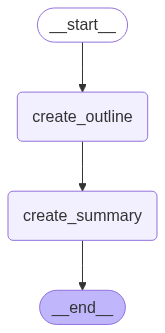

In [41]:
workflow

In [42]:
initial_state = {"image_path": "dashboard2.jpg"}

final_state = workflow.invoke(initial_state)

In [43]:
final_state

{'image_path': 'dashboard2.jpg',
 'image_base64': '...',
 'outline': '- **Personal Overview**\n  - Title/Topic: Personal Progress Dashboard\n  - Type: Text and Icon Layout\n  - Key Metrics: User information (Name: Ken Kalil, Email: kenK@gmail.com)\n  - Notable Features: Navigation menu with sections like Dashboard, Account Profile, etc.\n\n- **Chart 1 — Personal Progress Overview**\n  - Title/Topic: Activity Cycle\n  - Type: Circular Flow Chart\n  - Key Metrics: Six steps or activities denoted by circular icons\n  - Notable Trends: Sequential order from 1 to 6, no specific data trends\n\n- **Chart 2 — Cardio Activities**\n  - Title/Topic: Cardio\n  - Type: Donut Chart\n  - Key Metrics: Swimming, Spinning, Running, Biking\n  - Notable Trends: Equal segments among activities\n\n- **Chart 3 — Climbing Inclination**\n  - Title/Topic: Climbing Inclination\n  - Type: Line Chart\n  - Key Metrics: Incline over time\n  - Notable Trends: Highlighted data point on October 17 with a reference valu

In [44]:
print(final_state["outline"])

- **Personal Overview**
  - Title/Topic: Personal Progress Dashboard
  - Type: Text and Icon Layout
  - Key Metrics: User information (Name: Ken Kalil, Email: kenK@gmail.com)
  - Notable Features: Navigation menu with sections like Dashboard, Account Profile, etc.

- **Chart 1 — Personal Progress Overview**
  - Title/Topic: Activity Cycle
  - Type: Circular Flow Chart
  - Key Metrics: Six steps or activities denoted by circular icons
  - Notable Trends: Sequential order from 1 to 6, no specific data trends

- **Chart 2 — Cardio Activities**
  - Title/Topic: Cardio
  - Type: Donut Chart
  - Key Metrics: Swimming, Spinning, Running, Biking
  - Notable Trends: Equal segments among activities

- **Chart 3 — Climbing Inclination**
  - Title/Topic: Climbing Inclination
  - Type: Line Chart
  - Key Metrics: Incline over time
  - Notable Trends: Highlighted data point on October 17 with a reference value (11,004)

- **Chart 4 — Progress Tracking**
  - Title/Topic: Progress Tracking
  - Type: B

In [45]:
print(final_state["summary"])

The Personal Progress Dashboard presents an engaging overview of Ken Kalil's personal activities and achievements, blending a variety of charts and graphs for intuitive insight. This dashboard is structured with ease of navigation and user details prominently displayed alongside a range of progress indicators, offering a comprehensive view of Ken's physical activities.

At the heart of the dashboard is the 'Activity Cycle', a Circular Flow Chart with six sequential steps or activities. While this chart does not highlight specific data trends, it visually captures the structured routine of Ken’s workout regimen. Accompanying this is the 'Cardio Activities' Donut Chart that equally represents Ken’s diverse cardio regime, encompassing swimming, spinning, running, and biking. The equal distribution suggests a balanced approach to his cardio workouts.

The dashboard features a 'Climbing Inclination' Line Chart, where a pivotal data point is highlighted on October 17, noting an incline value